# Differential Algebraic Equations (DAEs)
**Prepared by:** Prof. Alexander Dowling, Myia Dickens (mdicken2@nd.edu, 2023), Molly Dougher (mdoughe6@nd.edu, 2023)

Classify a dynamic model, expose the pendulum's hidden constraints, and prepare consistent initial values. Compare a pure-ODE reduction, a coordinate-based DAE and an acceleration-only DAE using their equations, solver behavior and residuals. This guide supplies the complete derivations and computations that supplement Lecture 5.

In [1]:
import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    !pip install casadi
    import helper

    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper
helper.set_plotting_style()

## Software used

* [Pyomo.DAE](https://pyomo.readthedocs.io/en/latest/explanation/modeling/dae.html) expresses differential and algebraic equations and can discretize them for optimization.
* [CasADi](https://web.casadi.org/docs/) provides the interface used by `Pyomo.DAE.Simulator`; its `idas` plugin calls the SUNDIALS IDA integrator.

The notebook catches expected failures so subsequent formulations can run. A caught `IDA_CONV_FAIL` is evidence about the high-index formulation, not a notebook error.

(dae-dynamic-optimization)=
## Dynamic optimization and variable roles

For fixed initial and final times, a semiexplicit dynamic optimization problem is

$$
\begin{aligned}
\min_{\mathbf u(\cdot),\mathbf p}\quad&\Phi(\mathbf z(t_f),\mathbf y(t_f),\mathbf u(t_f),\mathbf p)\\
\text{s.t.}\quad&\dot{\mathbf z}(t)=\mathbf f(\mathbf z(t),\mathbf y(t),\mathbf u(t),\mathbf p),\\
&\mathbf g(\mathbf z(t),\mathbf y(t),\mathbf u(t),\mathbf p)=\mathbf0,\\
&\mathbf u_L\le\mathbf u(t)\le\mathbf u_U,\quad\mathbf p_L\le\mathbf p\le\mathbf p_U,\\
&\mathbf y_L\le\mathbf y(t)\le\mathbf y_U,\quad\mathbf z_L\le\mathbf z(t)\le\mathbf z_U,\\
&\mathbf h(\mathbf p,\mathbf z(t_0),\mathbf z(t_f))=\mathbf0,\quad t\in[t_0,t_f].
\end{aligned}
$$

The control trajectory $\mathbf u(t)$ and time-independent parameters $\mathbf p$ are **decisions**. The differential states $\mathbf z(t)$ and algebraic variables $\mathbf y(t)$ respond to those choices through the DAE and boundary conditions. Controls may themselves have a finite parameterization; bounds alone do not specify that parameterization. Here $\mathbf f$ denotes a differential right-hand side, $\mathbf g$ algebraic equations, and $\mathbf h$ boundary conditions. Their roles differ from the objective and constraint notation used for a static NLP.

Source: Biegler (2010), Chapter 8, *Introduction to Dynamic Process Optimization*, Eqs. (8.2), (8.5), pp. 214–216. The p. 216 erratum expands the bound reference to all of (8.5d)–(8.5g).

![Decision trajectories and parameters determine a feasible DAE response](../../media/figures/dae-variable-roles.png)

(dae-model-forms)=
### Explicit, mass-matrix and fully implicit forms

An explicit ODE is $\dot{\mathbf z}=\mathbf f(t,\mathbf z)$. A semiexplicit DAE combines $\dot{\mathbf z}=\mathbf f(t,\mathbf z,\mathbf y)$ with $\mathbf g(t,\mathbf z,\mathbf y)=\mathbf0$. Stack $\mathbf x=(\mathbf z,\mathbf y)$ to write the fully implicit residual form $\mathbf F(t,\mathbf x,\dot{\mathbf x})=\mathbf0$. A nonsingular $\mathbf F_{\dot x}$ permits local solution for $\dot{\mathbf x}$ by the implicit function theorem; a fully implicit notation alone does not make an equation a DAE.

In the special mass-matrix form $\mathbf M\dot{\mathbf x}=\mathbf f(t,\mathbf x)$, a semiexplicit DAE has $\mathbf M=\operatorname{diag}(\mathbf I,\mathbf0)$. Algebraic rows have no derivative. A general singular mass matrix need not already have zero rows; transformations can be needed to expose its structure.

![The semi-explicit mass matrix has zero derivative rows for the algebraic equations](../../media/figures/dae-mass-matrix.png)

Examples: a tank with $\dot h=q_{in}-q_{out}$ and $q_{out}=k\sqrt h$ is a semiexplicit DAE, smooth on $h>0$, with algebraic Jacobian $\partial g/\partial q_{out}=1$. A circuit with $C\dot V=i$ and $V_s-V-Ri=0$ is semiexplicit for $C>0$; $i$ can be eliminated when $R\ne0$. The decay model $\dot c=-kc$ is an explicit ODE.

Sources: Biegler, Eq. (8.1), p. 214; Ascher & Petzold (1998), §1.3, Eqs. (1.10)–(1.11), p. 10.

(dae-implicit-function)=
## Local elimination and solution branches

Fix the controls and parameters. Suppose $\mathbf g:\mathbb R^{n_z}\times\mathbb R^{n_y}\to\mathbb R^{n_y}$ is continuously differentiable near a feasible point $(\mathbf z^*,\mathbf y^*)$ and $\mathbf g_y(\mathbf z^*,\mathbf y^*)$ is nonsingular. The **implicit function theorem** gives open neighborhoods $U,V$ and a unique continuously differentiable map $\boldsymbol\psi:U\to V$ with $\boldsymbol\psi(\mathbf z^*)=\mathbf y^*$ and

$$\mathbf g(\mathbf z,\boldsymbol\psi(\mathbf z))=\mathbf0\quad\text{for every }\mathbf z\in U.$$

Uniqueness concerns solutions in $U\times V$. Other branches can exist elsewhere. If $\mathbf g\in C^p$ then $\boldsymbol\psi\in C^p$, and differentiating the identity gives

$$\mathbf g_z+\mathbf g_y\boldsymbol\psi_z=\mathbf0,
\qquad\boldsymbol\psi_z=-\mathbf g_y^{-1}\mathbf g_z.$$

The reduced ODE is $\dot{\mathbf z}=\mathbf f(t,\mathbf z,\boldsymbol\psi(\mathbf z))$. Local ODE uniqueness additionally needs regularity of this right-hand side, for example local Lipschitz continuity in $\mathbf z$. If $\mathbf g$ depends explicitly on time, differentiate with the additional term $\mathbf g_t$; prescribed smooth controls add $\mathbf g_u\dot{\mathbf u}$.

![Two branches of an algebraic equation, a regular local neighborhood and the singular meeting point](https://raw.githubusercontent.com/ndcbe/optimization/ad05ea88167b8998682df0020489e5ccf4c53a8c/media/figures/dae-local-branches.png)

A **solution branch** is a continuous local sheet of feasible points. For $g(z,y)=y^2-z$, the positive and negative sheets are $y=\pm\sqrt z$ on $z>0$. At $(1,1)$, $g_y=2$ and the positive branch has slope $1/(2\sqrt z)$. Both branches meet at $(0,0)$, where $g_y=0$ and neither is a differentiable graph over an open interval about $z=0$. Loss of nonsingularity removes the theorem's guarantee; it does not by itself prove nonuniqueness. For example, $y^3-z=0$ has a unique real solution $y=\sqrt[3]z$ at every $z$, but this map is not differentiable at zero.

Sources: Nocedal & Wright (2006), Theorem A.2, p. 631; Biegler, Eq. (8.3), p. 215.

(dae-index-reduction)=
## Differentiation index and index reduction

For the fixed controls and parameters, the **differentiation index** is the least number of time differentiations needed to determine an ODE for all variables locally. This is the convention used here; other DAE indices require their own definitions. An explicit ODE has index 0. At a regular semiexplicit point,

$$\mathbf0=\frac{d\mathbf g}{dt}=\mathbf g_z\mathbf f+\mathbf g_y\dot{\mathbf y}
\quad\Longrightarrow\quad\dot{\mathbf y}=-\mathbf g_y^{-1}\mathbf g_z\mathbf f,$$

so one differentiation suffices. Keep explicit time/control derivative terms when present.

Biegler's Algorithm 8.1 reduces a high-index semiexplicit system as follows:

1. Check whether the algebraic Jacobian is nonsingular for the chosen differential/algebraic partition. If it is, stop.
2. Identify algebraic equations that determine a subset of the algebraic variables.
3. Differentiate remaining algebraic equations containing differential variables.
4. Substitute differential right-hand sides. Replace selected differential equations by the differentiated algebraic equations and reclassify the corresponding variables as algebraic.
5. Recheck the new algebraic Jacobian. Preserve the original constraints as consistency conditions and monitor the validity of the chosen coordinates.

The method needs local regularity, consistent initial data and a valid equation-variable pairing. Counting `DerivativeVar` declarations alone does not establish the index. Structural analysis identifies differentiations and variable selections; numerical rank and conditioning must still be checked. See @pantelides1988consistent and @pryce2001structural.

Source: Biegler, Definition 8.6, p. 232; Eq. (8.37), pp. 233–234; Algorithm 8.1, p. 234. The distinction between DAE and ODE numerical methods is developed by @petzold1982daes and @gear1984odemethods.

(dae-holonomic-index)=
### Why regular holonomic mechanics gives index 3

Consider smooth position constraints $\mathbf c(\mathbf q)=\mathbf0$ with full-row-rank Jacobian $\mathbf G=\mathbf c_{\mathbf q}$, and equations $\mathbf M(\mathbf q)\ddot{\mathbf q}=\mathbf a(\mathbf q,\dot{\mathbf q})-\mathbf G^T\boldsymbol\lambda$ with positive definite mass matrix $\mathbf M$. The original first-order DAE uses positions and velocities as differential variables and multipliers as algebraic variables.

One differentiation gives $\mathbf G\dot{\mathbf q}=\mathbf0$. A second gives $\mathbf G\ddot{\mathbf q}+\dot{\mathbf G}\dot{\mathbf q}=\mathbf0$, so substitution yields

$$\mathbf G\mathbf M^{-1}\mathbf G^T\boldsymbol\lambda
=\mathbf G\mathbf M^{-1}\mathbf a+\dot{\mathbf G}\dot{\mathbf q}.$$

The coefficient is nonsingular: for $\mathbf w\ne\mathbf0$, full row rank implies $\mathbf G^T\mathbf w\ne\mathbf0$, and $\mathbf w^T\mathbf G\mathbf M^{-1}\mathbf G^T\mathbf w>0$. Thus the second derivative determines the force multipliers; one further differentiation determines their time derivatives. This regular holonomic formulation has differentiation index 3. Redundant geometry, a singular mass model, or a different formulation can change the conclusion; arbitrary mechanical DAEs do not automatically have index 3. The pendulum ladder below illustrates these three levels.

Sources: Ascher & Petzold, §9.1.1, Examples 9.6–9.7, pp. 241–242, and §9.2.1, pp. 248–249.


## Pendulum model and index reduction
The pendulum follows Ascher and Petzold, §1.3 and §9.1–§9.2. Compare the original index-3 model with pure-ODE and locally index-1 reformulations.

![Simple pendulum: mass $m=1$ on a rigid link of length $L=1$, with angle $\theta$ from vertical.](https://raw.githubusercontent.com/ndcbe/optimization/ad05ea88167b8998682df0020489e5ccf4c53a8c/media/figures/pendulum.png)

![Successive differentiation exposes tangent velocity, acceleration and the multiplier derivative](../../media/figures/dae-constraint-levels.png)

The following DAE system describes the pendulum system:

\begin{align}
& x' = u \\
& y' = v \\
& u' = -Tx \\
& v' = g - Ty \\
& x^2 + y^2 = 1 \\
\end{align}

To find the index of the DAE system, first take the derivative of the algebraic equation and substitute in for the differential variables:

\begin{align}
& x^2 + y^2 = 1 \\
& 2xx' + 2yy' = 0 \\
& 2xu + 2yv = 0
\end{align}

Next, differentiate the obtained equation using the product rule, make similar substitutions, and rearrange:

\begin{align}
& 2xu + 2yv = 0 \\
& 2(xu'+ x'u) + 2(yv' + vy') = 0 \\
& 2(-Tx^2 + u^2) + 2(y(g-Ty) + v^2) = 0 \\
& 2(u^2 + v^2) + 2(-Tx^2 + gy - Ty^2) = 0 \\
& 2(u^2 + v^2) - 2T(x^2 + y^2) + 2gy = 0
\end{align}

Finally, implicitly differentiate the obtained equation, make similar substitutions, and rearrange to isolate the $T'$ term:

\begin{align}
& 2(u^2 + v^2) - 2T(x^2 + y^2) + 2gy = 0 \\
& 4(uu' + vv') - 4T(xx' + yy') - 2T'(x^2 + y^2) + 2gy' = 0 \\
& 4(uu' + vv') - 4T(xx' + yy') + 2gy' = 2T'(x^2 + y^2) \\
& 4(-Tux + v(g-Ty)) - 4T(xu + yv) + 2gv = 2T'(x^2+y^2) \\
& 4(-Tux -Tyv + gv) - 4T(xu + yv) + 2gv = 2T'(x^2+y^2) 
\end{align}

Thus

$$T'=\frac{-4T(xu+yv)+3gv}{x^2+y^2},$$

with the denominator retained during the differentiation. The numerator contains two product-rule contributions of $-2T(xu+yv)$, giving $-4T(xu+yv)$ in total. Now the equations are a system of ODEs on $x^2+y^2>0$. Three differentiations were completed, indicating that this is an **Index 3 DAE**.

![Replacing selected differential equations changes the differential and algebraic partition](../../media/figures/dae-state-selection.png)

To reduce this DAE to index 1, follow Algorithm 8.1. The above analysis shows that this is not an index 1 DAE system. Therefore, the following algebraic equation is identified: $x^2 + y^2 = 1$. Differentiate the algebraic equation to yield:
\begin{align}
& 2xx' + 2yy' = 0\\
\end{align}
which can be solved for $x'$. Substitute for $x'$ and $y'$ to yield:
\begin{align}
& 2xu + 2yv = 0\\
\end{align}
The new DAE system is now:
\begin{align}
& y' = v \\
& u' = -Tx \\
& v' = g - Ty \\
& x^2 + y^2 = 1 \\
& 2xu + 2yv = 0 \\
\end{align}
where $(x,T)$ are algebraic variables. Neither algebraic equation contains $T$, so their Jacobian has a zero $T$ column; this intermediate system is not index 1. Differentiate the velocity constraint to obtain:
\begin{align}
& 2(xu'+ x'u) + 2(yv' + vy') = 0 \\
& 2(xu' + u^2) + 2(yv' + v^2) = 0 \\
& 2(u^2 - Tx^2) + 2(v^2 + gy - Ty^2) = 0 \\
\end{align}
The equations can replace $u' = -Tx$, leading to the following DAE system:
\begin{align}
& y' = v \\
& v' = g - Ty \\
& x^2 + y^2 = 1 \\
& 2xu + 2yv = 0 \\
& (u^2 + v^2) - T\underbrace{(x^2 + y^2)}_{1} + gy = 0 \\
\end{align}
which is an **index-1 DAE wherever $x\ne0$**. Its algebraic Jacobian and the scope of this statement are derived below.

In [2]:
## Load libraries
import pyomo.environ as pyo
import pyomo.dae as dae
from pyomo.dae.simulator import Simulator
import matplotlib.pyplot as plt
import numpy as np


## Define function for plotting results
def plot_results(sim, tsim, profiles):
    """
    inputs:

    sim: pyomo.DAE simulator results from a simulation of ODE or DAE
    tsim: 1D array of time samples of the DAE/ODE simulatiion
    profiles: 2D array of simulated differential and algebraic equations

    outputs:

    Plot 1: A plot of the curated profiles
    Plot 2: A plot of the simulated results

    time = list(m.t)
    x = [value(m.x[t]) for t in m.t]
    y = [value(m.y[t]) for t in m.t]

    plt.plot(time, x, '-b', label='x')
    plt.plot(time, y, '-r', label='y')
    plt.xlabel('Time')
    plt.ylabel('Position')
    plt.legend(loc='best')
    plt.show()
    """

    plt.figure(figsize=(5, 4))

    # Every series also carries a linestyle, so the figure survives a
    # black-and-white printout (figures/README.md).
    linestyles = ["-", "--", "-.", ":", (0, (3, 1, 1, 1, 1, 1))]

    varorder = sim.get_variable_order()
    algorder = sim.get_variable_order(vartype="algebraic")

    # Create empty dictionary
    results = {}

    # Collect Different Profiles
    for idx1, v in enumerate(varorder):
        i = idx1
        v_ = str(v)
        results[v_] = profiles[:, i]
        plt.plot(tsim, results[v_], label=v, linestyle=linestyles[i % len(linestyles)])

    # Collect Algebraic Profiles
    for idx2, v in enumerate(algorder):
        i = len(varorder) + idx2
        v_ = str(v)
        results[v_] = profiles[:, i]
        plt.plot(tsim, results[v_], label=v, linestyle=linestyles[i % len(linestyles)])

    # Plot the simulated algebraic and differential profiles as they change in time
    plt.xlabel("t", fontsize=16, fontweight="bold")
    plt.tick_params(direction="in", labelsize=15)
    plt.legend(loc="best")

    plt.show()

    # Plot the results of the simulation
    plt.figure(figsize=(5, 4))
    x_ = results["x[{t}]"]
    y_ = results["y[{t}]"]
    plt.plot(tsim, np.sqrt(x_**2 + y_**2), "-b", label="length")
    plt.xlabel("t", fontsize=16, fontweight="bold")
    plt.tick_params(direction="in", labelsize=15)
    plt.ylabel(r"$\sqrt{x^2 + y^2}$")
    plt.show()

    # return results

### Formulation 1: Index-3 DAE

Consider the following model:

$$\begin{align}
\frac{d x}{dt} &= u \\
\frac{d y}{dt} &= v \\
\frac{d u}{dt} &= -T x \\
\frac{d v}{dt} &= g - Ty \\
& x^2 + y^2 = 1
\end{align}$$

This assumes mass and length of unity.

### Sign convention and units

Coordinates are measured from the pivot, with $y$ positive **downward**. The model assumes a rigid link with length $L=1$ and mass $m=1$. In dimensional coordinates, $x^2+y^2=L^2$ and $T$ has units $\mathrm{s}^{-2}$: physical axial force divided by $mL$. A rigid rod can transmit compression; a taut-rope interpretation needs an additional nonnegative-tension condition.

This normalized example uses dimensionless numerical literals in Pyomo. It therefore does not attach unit objects to each declaration. A dimensional implementation must carry $L^2$ and the correct force scaling throughout; the [units and Pyomo.DAE guide](./units_and_pyomo_dae.md) demonstrates explicit unit handling. The dimensional check below verifies the third differentiation independently.

In [3]:
def add_index3_structure(m):
    # Four differential variables; the position constraint contains no T.
    m.dx = dae.DerivativeVar(m.x)  # with respect to t is implied

    m.dy = dae.DerivativeVar(m.y)

    m.du = dae.DerivativeVar(m.u)

    m.dv = dae.DerivativeVar(m.v)

    @m.Constraint(m.t)
    def alg_eqn(m, t):
        return m.x[t] ** 2 + m.y[t] ** 2 == 1


In [4]:
def create_model_index3():
    """
    Creates a model to define the Index 3 DAE system.

    Output: the model, m
    """

    m = pyo.ConcreteModel()

    # Declare time
    m.t = dae.ContinuousSet(bounds=(0.0, 1))

    # Declare parameter - acceleration due to gravity
    m.g = pyo.Param(initialize=9.81)  # [m/s^2]

    # Declare variables indexed over time
    m.x = pyo.Var(m.t)  # horizontal position
    m.y = pyo.Var(m.t)  # vertical position
    m.u = pyo.Var(m.t)  # horizontal velocity
    m.v = pyo.Var(m.t)  # vertical velocity
    m.T = pyo.Var(m.t)  # tension

    # Four DerivativeVars: x, y, u and v all get one. Compare the index-1
    # model, which declares only two. Nothing below records that this system is
    # index 3 -- Pyomo has no notion of index, so the failure arrives at RUN
    # time, not build time: IDAS is written for index 0 and 1 and returns
    # IDA_CONV_FAIL at t = 0.
    # Declare derivative variables
    add_index3_structure(m)

    # Declare differential equations
    @m.Constraint(m.t)
    def dx_eqn(m, t):
        return m.dx[t] == m.u[t]

    @m.Constraint(m.t)
    def dy_eqn(m, t):
        return m.dy[t] == m.v[t]

    @m.Constraint(m.t)
    def du_eqn(m, t):
        return m.du[t] == -m.T[t] * m.x[t]

    @m.Constraint(m.t)
    def dv_eqn(m, t):
        return m.dv[t] == m.g - m.T[t] * m.y[t]


    # Specify initial conditions
    m.x[0] = 0
    m.y[0] = 1
    m.u[0] = 1
    m.v[0] = 0
    m.T[0] = 1 + m.g

    return m

In [5]:
index3 = create_model_index3()

# Specify integrator options
int_ops = {"print_stats": True, "abstol": 1e-8, "reltol": 1e-6}

# Solve DAEs
sim = Simulator(index3, package="casadi")
try:
    tsim, profiles = sim.simulate(
        numpoints=100, integrator="idas", integrator_options=int_ops
    )
except RuntimeError:
    # Expected: IDAS supports index-0 and index-1 DAEs, not this index-3 model.
    print("Expected IDAS failure: IDA_CONV_FAIL for the unreduced index-3 pendulum.")
else:
    plot_results(sim, tsim, profiles)

Expected IDAS failure: IDA_CONV_FAIL for the unreduced index-3 pendulum.


CasADi - 2026-10-17 05:24:28 WARNING("The options 't0', 'tf', 'grid' and 'output_t0' have been deprecated.
The same functionality is provided by providing additional input arguments to the 'integrator' function, in particular:
 * Call integrator(..., t0, tf, options) for a single output time, or
 * Call integrator(..., t0, grid, options) for multiple grid points.
The legacy 'output_t0' option can be emulated by including or excluding 't0' in 'grid'.
Backwards compatibility is provided in this release only.") [.../casadi/core/integrator.cpp:698]
At t = 0 and h = 1.06624e-14, the corrector convergence failed repeatedly or with |h| = hmin.


```{warning}
The `IDA_CONV_FAIL` printed above is expected: the unreduced pendulum is index 3. The exception is caught so the notebook can continue to the reformulations.
```

IDA solves implicit DAEs in residual form and is intended for index-1 systems. Here it repeatedly fails the corrector at $t=0$ and returns `IDA_CONV_FAIL`; reducing the model to index 0 or 1 is part of the modeling workflow, not a change of tolerances. See the [SUNDIALS IDA documentation](https://sundials.readthedocs.io/en/latest/ida/Introduction_link.html).

![The unreduced model fails the IDAS corrector at the initial time](../../media/figures/dae-index3-solver.png)


### Formulation 2: Pure ODE Model/ Index-0 Example

$$\begin{align}
\frac{d x}{dt} &= u \\
\frac{d y}{dt} &= v \\
\frac{d u}{dt} &= -T x \\
\frac{d v}{dt} &= g - Ty \\
\frac{d T}{dt} &= \frac{-4T(xu+yv)+3gv}{x^2+y^2}
\end{align}$$


FORWARD INTEGRATION:
Number of steps taken by SUNDIALS: 172
Number of calls to the user's f function: 236
Number of calls made to the linear solver setup function: 25
Number of error test failures: 6
Method order used on the last internal step: 5
Method order to be used on the next internal step: 5
Actual value of initial step size: 7.90569e-07
Step size taken on the last internal step: 0.0158106
Step size to be attempted on the next internal step: 0.0316212
Current internal time reached: 5
Number of nonlinear iterations performed: 234
Number of nonlinear convergence failures: 0



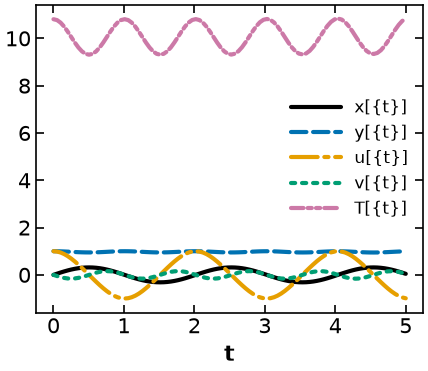

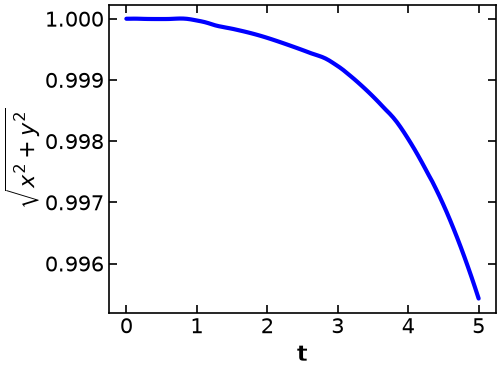

In [6]:
def create_model_ode():
    """
    Creates a model to define the Index 0 DAE system.

    Output: the model, m
    """

    m = pyo.ConcreteModel()

    # Declare time
    m.t = dae.ContinuousSet(bounds=(0.0, 5.0))

    # Declare parameter - acceleration due to gravit
    m.g = pyo.Param(initialize=9.81)  # [m/s^2]

    # Declare variables indexed over time
    m.x = pyo.Var(m.t)  # horizontal position
    m.y = pyo.Var(m.t)  # vertical position
    m.u = pyo.Var(m.t)  # horizontal velocity
    m.v = pyo.Var(m.t)  # vertical velocity
    m.T = pyo.Var(m.t)  # tension

    # Declare derivative variables
    m.dx = dae.DerivativeVar(m.x)  # with respect to t is implied
    m.dy = dae.DerivativeVar(m.y)
    m.du = dae.DerivativeVar(m.u)
    m.dv = dae.DerivativeVar(m.v)
    m.dT = dae.DerivativeVar(m.T)

    # Declare differential equations
    @m.Constraint(m.t)
    def dx_eqn(m, t):
        return m.dx[t] == m.u[t]

    @m.Constraint(m.t)
    def dy_eqn(m, t):
        return m.dy[t] == m.v[t]

    @m.Constraint(m.t)
    def du_eqn(m, t):
        return m.du[t] == -m.T[t] * m.x[t]

    @m.Constraint(m.t)
    def dv_eqn(m, t):
        return m.dv[t] == m.g - m.T[t] * m.y[t]

    @m.Constraint(m.t)
    def dT_eqn(m, t):
        return (
            m.dT[t]
            == (
                -4 * m.T[t] * (m.x[t] * m.u[t] + m.y[t] * m.v[t])
                + 3 * m.g * m.v[t]
            ) / (m.x[t] ** 2 + m.y[t] ** 2)
        )

    # Specify initial conditions
    m.x[0] = 0
    m.y[0] = 1
    m.u[0] = 1
    m.v[0] = 0
    m.T[0] = 1 + m.g

    return m


ode = create_model_ode()

# Specify integrator options
int_ops = {"print_stats": True, "abstol": 1e-6, "reltol": 1e-4}

# Solve DAEs
sim = Simulator(ode, package="casadi")
tsim, profiles = sim.simulate(
    numpoints=100, integrator="idas", integrator_options=int_ops
)

# Plot solution
results = plot_results(sim, tsim, profiles)

(dae-invariant-set)=
### What the differentiated constraints preserve

Define $\mathbf X=(x,y,u,v,T)$, $r^2=x^2+y^2$, and

$$h_1=r^2-1,\qquad h_2=xu+yv,\qquad h_3=u^2+v^2-Tr^2+gy.$$

For the five-state pure ODE, direct differentiation gives the exact residual chain

$$\dot h_1=2h_2,\qquad\dot h_2=h_3,\qquad\dot h_3=0.$$

![Residual chain from position to velocity to acceleration, including consistent and perturbed initial data](https://raw.githubusercontent.com/ndcbe/optimization/ad05ea88167b8998682df0020489e5ccf4c53a8c/media/figures/dae-constraint-chain.png)

Thus $h_3(t)=h_3(0)$, $h_2(t)=h_2(0)+t h_3(0)$ and $h_1(t)=h_1(0)+2t h_2(0)+t^2h_3(0)$. The set $\mathcal M=\{\mathbf X:\mathbf h(\mathbf X)=\mathbf0\}$ is invariant: exact integration from consistent data stays in it. The three functions are not all first integrals off this set. A perturbation in the acceleration residual can produce quadratic position drift; a velocity residual produces linear drift. Numerical truncation and roundoff can seed these residuals. Drift depends on the discretization and problem; it is not inevitable for every scheme.

**Consistent initial data.** On the unit circle, velocities must be tangent, $xu+yv=0$, and $T=(u^2+v^2+gy)/(x^2+y^2)$. At rest at $(-1/\sqrt2,1/\sqrt2)$, this gives $T=g/\sqrt2$. The longer-horizon numerical experiment below instead starts at $(0,1,1,0,1+g)$, which also satisfies all three conditions. Keep these two examples distinct.

Sources: Biegler, Eq. (8.37) and following discussion, pp. 233–234; Ascher & Petzold §9.2.1–§9.2.2, pp. 248–251. Their four-state mechanical reduction eliminates the multiplier algebraically. This five-state ODE carries its derivative, so its invariant set also includes $h_3=0$.

(dae-long-horizon-drift)=
### Drift and stabilization over a longer horizon

Integrate the same five-state ODE with SciPy RK45 on $[0,50]$, from $\mathbf X_0=(0,1,1,0,1+9.81)$. Compare relative tolerances $10^{-4}$ and $10^{-6}$, with absolute tolerance equal to one hundredth of the relative tolerance. The third run adds a constraint correction. The figure reports the computed length and the **running maximum** of $|\sqrt{x^2+y^2}-1|$. This differs from the squared-length residual and shorter IDAS experiment below; their curves should not be compared as if only the tolerance changed.

Let $\mathbf H=\partial\mathbf h/\partial\mathbf X$. A stabilization of the invariant set is

$$\dot{\mathbf X}=\widehat{\mathbf f}(\mathbf X)-\gamma\mathbf H^T(\mathbf H\mathbf H^T)^{-1}\mathbf h(\mathbf X),\qquad\gamma=5.$$

It requires full row rank of $\mathbf H$ in the neighborhood used. All three residuals are included because $T$ is a state here. With

$$\mathbf H=\begin{bmatrix}2x&2y&0&0&0\\u&v&x&y&0\\-2Tx&-2Ty+g&2u&2v&-r^2\end{bmatrix},$$

the corrected residual dynamics are $\dot{\mathbf h}=(\mathbf A-\gamma\mathbf I)\mathbf h$, where $A_{12}=2$, $A_{23}=1$, and all other entries vanish. The eigenvalues are $-\gamma$; hence the zero residual state is attracting for $\gamma>0$ as long as the correction is defined. This does not assert that every nonlinear extension or an arbitrary $\gamma$ gives a well-conditioned numerical problem. The correction vanishes on $\mathcal M$ and preserves the intended exact trajectory there.

Source: Ascher & Petzold, §9.2.2, Eqs. (9.40)–(9.42), pp. 250–251; @baumgarte1972stabilization provides a classical mechanical constraint-stabilization approach. The projection used here follows Ascher & Petzold's formula with $D=H^T$.

In [7]:
from scipy.integrate import solve_ivp

G = 9.81
T_END = 50.0
X0 = np.array([0.0, 1.0, 1.0, 0.0, 1.0 + G])  # x, y, u, v, T
GAMMA = 5.0


def rhs(t, X):
    """Attempt 2: the index-reduced pure ODE."""
    x, y, u, v, T = X
    r2 = x * x + y * y
    return np.array(
        [u, v, -T * x, G - T * y, (-4.0 * T * (x * u + y * v) + 3.0 * G * v) / r2]
    )


def invariants(X):
    """h(x) = 0 -- the three equations that were differentiated away."""
    x, y, u, v, T = X
    return np.array(
        [x * x + y * y - 1.0, x * u + y * v, u * u + v * v - T * (x * x + y * y) + G * y]
    )


def invariant_jacobian(X):
    """H = h_x, 3 x 5: equations down the rows, variables across the columns."""
    x, y, u, v, T = X
    return np.array(
        [
            [2 * x, 2 * y, 0.0, 0.0, 0.0],
            [u, v, x, y, 0.0],
            [-2 * T * x, -2 * T * y + G, 2 * u, 2 * v, -(x * x + y * y)],
        ]
    )


def rhs_stabilized(t, X):
    """A&P (9.40), p. 251, with the orthogonal projection F = H^T (H H^T)^{-1}."""
    H = invariant_jacobian(X)
    return rhs(t, X) - GAMMA * (H.T @ np.linalg.solve(H @ H.T, invariants(X)))


def integrate(fun, rtol, t):
    sol = solve_ivp(fun, [0.0, T_END], X0, rtol=rtol, atol=1e-2 * rtol,
                    dense_output=True)
    assert sol.success and sol.t[-1] == T_END, sol.message
    Y = sol.sol(t)
    assert np.isfinite(Y).all()
    return np.sqrt(Y[0] ** 2 + Y[1] ** 2)


t = np.linspace(0.0, T_END, 1001)
results = {
    "t": t.tolist(), "initial_state": X0.tolist(), "gamma": GAMMA,
    "series": [
        {"radius": integrate(rhs, 1e-4, t).tolist(), "marker": "s",
         "label": r"pure ODE, rtol $10^{-4}$"},
        {"radius": integrate(rhs, 1e-6, t).tolist(), "marker": "o",
         "label": r"pure ODE, rtol $10^{-6}$"},
        {"radius": integrate(rhs_stabilized, 1e-4, t).tolist(), "marker": "^",
         "label": r"stabilized, rtol $10^{-4}$"},
    ],
}
for series in results["series"]:
    series["max_length_error"] = float(np.max(np.abs(np.asarray(series["radius"]) - 1)))
    print(series["label"], "max length error", series["max_length_error"])
helper.save_results(
    "pendulum-drift", results, notebook="notebooks/3-dev/DAE_background.ipynb",
    description="RK45 five-state pendulum length and running maximum length error, with consistent initial values and an invariant-set correction.",
    solver="SciPy RK45",
    source_cells=[("notebooks/3-dev/DAE_background.ipynb", "l5:drift-extract")],
)

pure ODE, rtol $10^{-4}$ max length error 0.26376887323579024
pure ODE, rtol $10^{-6}$ max length error 0.002722908800151136
stabilized, rtol $10^{-4}$ max length error 1.125228558263025e-05
[helper] wrote figures/results/pendulum-drift.json


[helper] wrote media/figures/pendulum-drift.png and .pdf


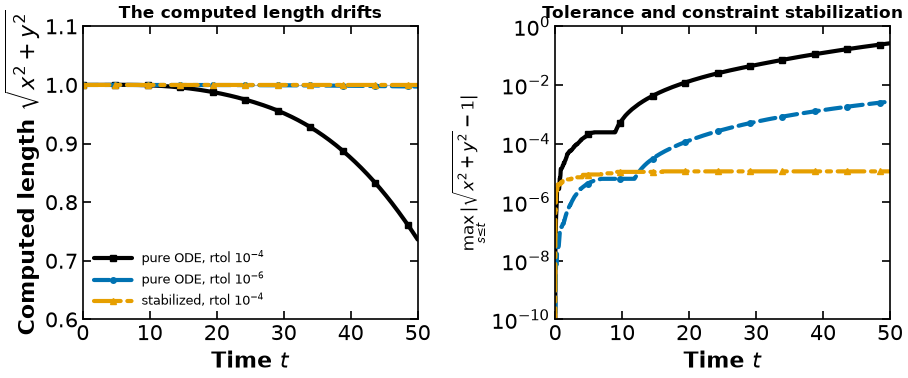

In [8]:
def plot_pendulum_drift(results):
    """Use archived radii; running maxima expose the accumulated length error."""
    t = np.asarray(results["t"])
    fig, (left, right) = plt.subplots(1, 2, figsize=(9.4, 4.1))
    for ax in (left, right):
        ax.set_xlabel("Time $t$")
        ax.set_xlim(t[0], t[-1])
        for spine in ax.spines.values():
            spine.set_color("black")
        ax.tick_params(colors="black")
    left.axhline(1, color="0.7", linewidth=0.8)
    for series in results["series"]:
        r = np.asarray(series["radius"])
        kw = {"marker": series["marker"], "markevery": 97, "markersize": 4,
              "label": series["label"]}
        left.plot(t, r, **kw)
        worst = np.maximum.accumulate(np.abs(r-1))
        right.semilogy(t, np.maximum(worst, 1e-16), **kw)
    left.set_ylabel(r"Computed length $\sqrt{x^2+y^2}$")
    left.set_ylim(0.6, 1.1)
    left.set_title("The computed length drifts", fontsize=12)
    right.set_ylabel(r"$\max_{s\leq t}|\sqrt{x^2+y^2}-1|$", fontsize=12)
    right.set_ylim(1e-10, 1)
    right.set_title("Tolerance and constraint stabilization", fontsize=12)
    left.legend(loc="lower left", fontsize=9)
    fig.tight_layout()
    return fig

fig = plot_pendulum_drift(results)
helper.save_figure(fig, "pendulum-drift")

#### Dimensional check

Restore units: $x,y$ in m; $u,v$ in m/s; and $T$ in $\mathrm{s}^{-2}$.

| Term | Units |
| --- | --- |
| $-4T(xu+yv)+3gv$ | $\mathrm{m}^2\,\mathrm{s}^{-3}$ |
| $x^2+y^2$ | $\mathrm{m}^2$ |
| quotient, $\dot T$ | $\mathrm{s}^{-3}$ |

The denominator is required dimensionally. Normalizing the rod length to one can hide
this factor algebraically, but not physically.


**Discussion**
* Are all of the algebraic constraints in the original formulation satisfied?

(dae-reduced-coordinate-model)=
### Formulation 3: a coordinate-based DAE

$$\begin{aligned}
\dot y&=v,&\dot v&=g-Ty,\\
x^2+y^2&=1,&xu+yv&=0,&u^2+v^2-T(x^2+y^2)+gy&=0.
\end{aligned}$$

The differential variables are $(y,v)$ and the algebraic variables are $(x,u,T)$. This is locally index 1 for $x\ne0$; it becomes singular at the vertical position $x=0$. Assign $(y_0,v_0)$ and select a branch, then solve the three algebraic equations for $(x_0,u_0,T_0)$. Interchanging the coordinate roles gives a different local chart.

(dae-coordinate-jacobian)=
## Coordinate singularity and recovery of the discarded equations

Use algebraic variables $(x,u,T)$ and rows $(xu+yv,\ u^2+v^2-Tr^2+gy,\ r^2-1)$. Their Jacobian is

$$\mathbf J=\begin{bmatrix}u&x&0\\-2Tx&2u&-r^2\\2x&0&0\end{bmatrix},\qquad\det\mathbf J=-2x^2r^2.$$

It is nonsingular for $x\ne0$ on the unit circle. At $x=0$ its third row vanishes. A nontrivial oscillatory swing crosses the vertical position; the equilibrium at the bottom remains there, while a rotating trajectory has different timing. The singularity occurs whenever this chart reaches $x=0$.

![Complementary coordinate charts on the pendulum circle, with their singular positions marked](https://raw.githubusercontent.com/ndcbe/optimization/ad05ea88167b8998682df0020489e5ccf4c53a8c/media/figures/dae-coordinate-charts.png)

**Why the regular reduction preserves the omitted dynamics.** Differentiate $r^2=1$ using the retained equation $\dot y=v$. Together with $xu+yv=0$ this gives $x(\dot x-u)=0$; at $x\ne0$, recover $\dot x=u$. Next differentiate $xu+yv=0$, substitute $\dot x=u$, $\dot y=v$, and $\dot v=g-Ty$. The acceleration constraint then gives $x(\dot u+Tx)=0$, so $\dot u=-Tx$ on the same regular branch. These are local deductions for continuous differentiable trajectories; discrete algebraic constraints at separated nodes alone do not enforce branch continuity.

Using differential variables $(x,u)$ instead gives algebraic variables $(y,v,T)$ and determinant $-2y^2r^2$ in the analogous row order. It works at $x=0,y\ne0$ and fails at $y=0$. Switching charts with consistent state transfer can avoid a particular partition's singularity. It does not remove a physical singularity from an intrinsically singular model.

The truncation error of the discarded equations $\dot x=u$ and $\dot u=-Tx$ is not estimated as their own differential equations in this partition. Algebraic error tests and residual control do not replace checking those omitted physical relations; their implicit equivalence requires a continuous regular branch. This statement does not mean that a DAE solver has no error tests for algebraic variables.

(dae-rank-remedies)=
### Pivoting, structural analysis and state selection

Row or column pivoting reorders a linear system to use stronger numerical pivots and limit unstable elimination. For permutation matrices $P,Q$, $\operatorname{rank}(PJQ)=\operatorname{rank}(J)$. Pivoting therefore cannot turn this rank-deficient Jacobian into a nonsingular one. Near a singular chart, monitor singular values or conditioning and change the equation-variable pairing before a failed solve. A numerical rank threshold must account for scaling.

- **State selection and dummy derivatives** replace selected derivatives by algebraic unknowns and choose a usable subsystem. See @mattsson1993dummy and the structural-selection refinements in @mckenzie2017dummy.
- **Structural analysis** exposes which equations to differentiate and helps construct consistent initialization: @pantelides1988consistent and @pryce2001structural. Structural nonsingularity does not guarantee good numerical conditioning.
- **Constraint stabilization** corrects residual dynamics, as derived above; it changes the off-manifold extension while preserving the constrained trajectory when the correction vanishes.
- **Runtime monitoring and coordinate reselection** keep a local formulation regular; they require consistent initialization after a switch.

Sources: Ascher & Petzold, §9.2.3, pp. 253–254; §9.1.2, pp. 245–247 for stability/conditioning. The actual solver and interface used here are described by @hindmarsh2005sundials and @andersson2019casadi. No solver failure code alone proves a particular mathematical cause: compare the residuals and Jacobian as well.

In [9]:
def add_coordinate_structure(m):
    # This partition is index 1 only where x != 0.
    m.dy = dae.DerivativeVar(m.y)

    m.dv = dae.DerivativeVar(m.v)

    @m.Constraint(m.t)
    def alg_eqn1(m, t):
        return m.x[t] ** 2 + m.y[t] ** 2 == 1

    @m.Constraint(m.t)
    def alg_eqn2(m, t):
        return m.x[t] * m.u[t] + m.y[t] * m.v[t] == 0

    @m.Constraint(m.t)
    def alg_eqn3(m, t):
        return (m.u[t]**2 + m.v[t]**2
                - m.T[t]*(m.x[t]**2 + m.y[t]**2) + m.g*m.y[t] == 0)


In [10]:
def create_model_index1():
    """
    Creates a model to define the Index 1 DAE system.

    Output: the model, m
    """

    m = pyo.ConcreteModel()

    # Declare time
    m.t = dae.ContinuousSet(bounds=(0, 5))

    # Declare parameter - acceleration due to gravity
    m.g = pyo.Param(initialize=9.81)  # [m/s^2]

    # Declare variables indexed over time
    m.x = pyo.Var(m.t)  # horizontal position
    m.y = pyo.Var(m.t)  # vertical position
    m.u = pyo.Var(m.t)  # horizontal velocity
    m.v = pyo.Var(m.t)  # vertical velocity
    m.T = pyo.Var(m.t)  # tension

    # y and v are differential; x, u and T are algebraic. This pairing
    # is index 1 only where the algebraic Jacobian is nonsingular (x != 0).
    # Two DerivativeVars specify the partition, not the index by themselves.
    add_coordinate_structure(m)

    # Declare differential equations
    @m.Constraint(m.t)
    def dy_eqn(m, t):
        return m.dy[t] == m.v[t]

    @m.Constraint(m.t)
    def dv_eqn(m, t):
        return m.dv[t] == m.g - m.T[t] * m.y[t]




    # Specify initial conditions
    m.x[0] = 0
    m.y[0] = 1
    m.u[0] = 1
    m.v[0] = 0
    m.T[0] = 1 + m.g

    return m

In [11]:
def index1_check_constraints(m):
    """Check if the three constraints are feasible."""

    print("Constraint 1:")
    r1 = m.x[0]() ** 2 + m.y[0]() ** 2 - 1
    print(r1)

    print("\nConstraint 2:")
    r2 = m.x[0]() * m.u[0]() + m.y[0]() * m.v[0]()
    print(r2)

    print("\nConstraint 3:")
    r3 = (
        m.u[0]() ** 2 + m.v[0]() ** 2
        - m.T[0]() * (m.x[0]() ** 2 + m.y[0]() ** 2)
        + m.g() * m.y[0]()
    )
    print(r3)
    residuals = (float(r1), float(r2), float(r3))
    # Compare the diagnostic with the actual model rows, including off-circle starts.
    model_residuals = tuple(
        pyo.value(getattr(m, name)[0].body - getattr(m, name)[0].lower)
        for name in ("alg_eqn1", "alg_eqn2", "alg_eqn3")
    )
    assert np.allclose(residuals, model_residuals, atol=1e-13, rtol=0)
    return residuals


index1 = create_model_index1()

# Check initial condition
index1_check_constraints(index1)

# Specify integrator options
int_ops = {"print_stats": True, "abstol": 1e-6, "reltol": 1e-4}

# Solve DAEs
sim = Simulator(index1, package="casadi")
try:
    tsim, profiles = sim.simulate(
        numpoints=100, integrator="idas", integrator_options=int_ops
    )
except RuntimeError as err:
    # Expected here: the reformulation is singular at x = 0.
    print(f"Expected point-singularity failure: {err}")
# tsim, profiles = sim.simulate(numpoints=100, integrator='collocation')

Constraint 1:
0

Constraint 2:
0

Constraint 3:
0.0
Expected point-singularity failure: Error in Function::call for 'F' [IdasInterface] at .../casadi/core/function.cpp:1466:
Error in Function::call for 'F' [IdasInterface] at .../casadi/core/function.cpp:362:
.../casadi/interfaces/sundials/idas_interface.cpp:599: IDACalcIC returned "IDA_NO_RECOVERY". Consult IDAS documentation.


The residual routine or the linear setup or solve routine had a recoverable error, but IDACalcIC was unable to recover.


What happened? The chosen algebraic equation--variable pairing is singular at $x=0$.

Let's try $x=0.1$ as the initial point.

In [12]:
index1_again = create_model_index1()

# Specify alternative initial conditions
small_number = 0.1

index1_again.x[0] = small_number
index1_again.y[0] = 1
index1_again.u[0] = 1
index1_again.v[0] = 0
index1_again.T[0] = 1 + index1_again.g

# Check initial condition
index1_check_constraints(index1_again)

# Solve DAEs
sim = Simulator(index1_again, package="casadi")

# Simulator
try:
    tsim, profiles = sim.simulate(
        numpoints=100, integrator="idas", integrator_options=int_ops
    )
except RuntimeError as err:
    # Expected here: these trial initial values violate the invariants.
    print(f"Expected inconsistent-initialization failure: {err}")

Constraint 1:
0.010000000000000009

Constraint 2:
0.1

Constraint 3:
-0.10810000000000031
Expected inconsistent-initialization failure: Error in Function::call for 'F' [IdasInterface] at .../casadi/core/function.cpp:1466:
Error in Function::call for 'F' [IdasInterface] at .../casadi/core/function.cpp:362:
.../casadi/interfaces/sundials/idas_interface.cpp:599: IDACalcIC returned "IDA_NO_RECOVERY". Consult IDAS documentation.


The residual routine or the linear setup or solve routine had a recoverable error, but IDACalcIC was unable to recover.


Our initial point does not satisfy the algebraic constraints! We need a consistent initial point.

Given $x = \epsilon$, solve $x^2 + y^2 = 1$ for $y$:

$$ y = \sqrt{1^2 - \epsilon^2}$$

Then, assume $u = 1$ and solve $2 x u + 2 y v = 0$ for $v$:

$$v = \frac{-x u}{y}$$

Finally, we can solve $(u^2 + v^2) - T (x^2 + y^2) + g y = 0$ for $T$:

$$
T = \frac{(u^2 + v^2) + gy}{x^2 + y^2} = \frac{(u^2 + v^2) + gy}{1}
$$

In [13]:
index1_take_two = create_model_index1()

# Specify alternative initial conditions
small_number = 0.1

index1_take_two.x[0] = small_number
index1_take_two.y[0] = np.sqrt(1 - small_number**2)
index1_take_two.u[0] = 1
index1_take_two.v[0] = (
    -index1_take_two.x[0]() * index1_take_two.u[0]() / index1_take_two.y[0]()
)
index1_take_two.T[0] = (
    index1_take_two.u[0]() ** 2
    + index1_take_two.v[0]() ** 2
    + index1_take_two.g * index1_take_two.y[0]()
)

# Check initial condition
coordinate_initial_residuals = index1_check_constraints(index1_take_two)

# Solve DAEs
sim = Simulator(index1_take_two, package="casadi")

# Specify integrator options
int_ops2 = {
    "print_stats": True,
    "abstol": 1e-6,
    "reltol": 1e-4,
    "verbose": False,
    "calc_ic": True,
}

# Simulator
coordinate_failure = None
try:
    tsim, profiles = sim.simulate(
        numpoints=20, integrator="idas", integrator_options=int_ops2
    )
except RuntimeError as err:
    coordinate_failure = str(err)
    # Preserve the actual initialization failure for the concise diagnostic.
    print(f"Expected formulation failure: {err}")

Constraint 1:
0.0

Constraint 2:
0.0

Constraint 3:
0.0
Expected formulation failure: Error in Function::call for 'F' [IdasInterface] at .../casadi/core/function.cpp:1466:
Error in Function::call for 'F' [IdasInterface] at .../casadi/core/function.cpp:362:
.../casadi/interfaces/sundials/idas_interface.cpp:599: IDACalcIC returned "IDA_NO_RECOVERY". Consult IDAS documentation.


The residual routine or the linear setup or solve routine had a recoverable error, but IDACalcIC was unable to recover.


(dae-algebraic-initial-guess)=
### A consistent model point must reach the integrator

The preceding failure is `IDACalcIC`, during **initialization**. It does not demonstrate a later vertical crossing: our point $x_0=0.1$ has a nonsingular algebraic Jacobian. The installed Pyomo Simulator's no-input CasADi path calls the integrator with `x0` for differential variables but supplies no `z0` for algebraic variables. Assigning Pyomo's initial algebraic values therefore does not pass them through this path. A default zero algebraic guess includes $x=0$, where this partition's algebraic Jacobian is singular.

The following small direct-CasADi diagnostic supplies both initial vectors for the same equations. The short regular interval succeeds. A longer request still encounters integration difficulty near the chart singularity; it is a separate issue from the missing algebraic initial guess. The run's actual messages are retained. The high-index failure above, the wrapper initialization failure here, and a later coordinate-chart failure must not be treated as the same evidence.

Sources: [Pyomo Simulator source, `_simulate_with_casadi_no_inputs`](https://pyomo.readthedocs.io/en/stable/_modules/pyomo/dae/simulator.html#Simulator); [IDA initial-condition requirements](https://sundials.readthedocs.io/en/latest/ida/Mathematics_link.html#initial-condition). These interface details were checked against the installed code; they can change across package versions.

In [14]:
import casadi as ca

q = ca.MX.sym("differential", 2)  # y, v
algebraic = ca.MX.sym("algebraic", 3)  # x, u, T
y, v = q[0], q[1]
x, u, T = algebraic[0], algebraic[1], algebraic[2]
chart_dae = {
    "x": q, "z": algebraic,
    "ode": ca.vertcat(v, 9.81 - T*y),
    "alg": ca.vertcat(x*x+y*y-1, x*u+y*v,
                      u*u+v*v-T*(x*x+y*y)+9.81*y),
}
q0 = [np.sqrt(0.99), -0.1/np.sqrt(0.99)]
z0 = [0.1, 1.0, 1/0.99+9.81*np.sqrt(0.99)]
residual_check = ca.Function("initial_residual", [q, algebraic], [chart_dae["alg"]])
assert np.max(np.abs(residual_check(q0,z0).full())) < 1e-13
seeded_chart_runs = []
for horizon in (0.1, 5.0):
    integrator = ca.integrator("seeded_chart", "idas", chart_dae, 0.0, horizon,
                              {"abstol":1e-8, "reltol":1e-6, "calc_ic":True})
    try:
        solution = integrator(x0=q0, z0=z0)
    except RuntimeError as err:
        assert horizon > 0.1, "The short regular-interval check must succeed"
        record = {"horizon":horizon, "status":"failed", "message":str(err)}
    else:
        record = {"horizon":horizon, "status":"success",
                  "differential_final":solution["xf"].full().ravel().tolist(),
                  "algebraic_final":solution["zf"].full().ravel().tolist()}
    seeded_chart_runs.append(record)
    print(record)

{'horizon': 0.1, 'status': 'success', 'differential_final': [0.9812057799466012, -0.16596004984792817], 'algebraic_final': [0.1929642904772332, 0.8438916845613251, 10.365324614693437]}
{'horizon': 5.0, 'status': 'failed', 'message': 'Error in Function::call for \'seeded_chart\' [IdasInterface] at .../casadi/core/function.cpp:1466:\nError in Function::call for \'seeded_chart\' [IdasInterface] at .../casadi/core/function.cpp:362:\n.../casadi/interfaces/sundials/idas_interface.cpp:599: IDASolve returned "IDA_TOO_MUCH_WORK". Consult IDAS documentation.'}


At t = 0.913642, , mxstep steps taken before reaching tout.


In [15]:
print("Pyomo initial residuals:", " ".join(f"{r:.1f}" for r in coordinate_initial_residuals))
if coordinate_failure:
    returned = coordinate_failure.split("returned ", 1)[-1].split(". Consult", 1)[0]
    print("Pyomo initialization:", returned)
for run in seeded_chart_runs:
    detail = run["status"]
    if run["status"] == "failed":
        detail = run["message"].split("returned ", 1)[-1].split(". Consult", 1)[0]
    print(f"Direct CasADi to t={run['horizon']}: {detail}")


Pyomo initial residuals: 0.0 0.0 0.0
Pyomo initialization: "IDA_NO_RECOVERY"
Direct CasADi to t=0.1: success
Direct CasADi to t=5.0: "IDA_TOO_MUCH_WORK"


(dae-collocation-initialization)=
### Direct collocation: initial conditions and a trajectory check

The coordinate partition becomes singular along this swing, even after a successful local start. Discretize that model using Radau collocation and solve the resulting feasibility NLP with Ipopt. Assigning `.value` supplies an **initial guess**; it does not impose an initial condition. We fix the two differential initial values $y_0,v_0$ and bound $x_0\ge0$ to select the intended positive initial branch. The algebraic equations determine $x_0,u_0,T_0$; fixing all five independently would add redundant restrictions.

A uniform initial guess can lead to local infeasibility. Seed all nodes using an independent angular ODE,

$$\dot\theta=\omega,\qquad\dot\omega=-g\sin\theta,$$

with $x=\sin\theta$, $y=\cos\theta$, $u=\omega\cos\theta$, $v=-\omega\sin\theta$, and $T=\omega^2+g\cos\theta$. Its initial data are $\theta_0=\arcsin(0.1)$ and $\omega_0=1/\sqrt{0.99}$. This reference supplies a reproducible initial guess and a separate accuracy diagnostic; it is not a constraint in the NLP.

In [16]:
from scipy.integrate import solve_ivp

reference = solve_ivp(
    lambda t, state: [state[1], -9.81 * np.sin(state[0])],
    (0.0, 5.0), [np.arcsin(0.1), 1 / np.sqrt(0.99)],
    method="DOP853", rtol=1e-12, atol=1e-14, dense_output=True,
)
assert reference.success and reference.t[-1] == 5.0, reference.message

# A feasibility problem, with physical initial conditions fixed separately.
index1_take_two.Obj = pyo.Objective(expr=1)
collocation_nfe = 30
pyo.TransformationFactory("dae.collocation").apply_to(
    index1_take_two, nfe=collocation_nfe, scheme="LAGRANGE-RADAU", ncp=3,
)
index1_take_two.y[0].fix(np.sqrt(0.99))
index1_take_two.v[0].fix(-0.1 / np.sqrt(0.99))
index1_take_two.x[0].setlb(0.0)  # select the positive initial branch only

# Seed the complete mesh, including derivative variables, from the angular ODE.
for t in index1_take_two.t:
    theta, omega = reference.sol(float(t))
    x, y = np.sin(theta), np.cos(theta)
    u, v = omega * y, -omega * x
    T = omega**2 + 9.81 * y
    for name, value in (
        ("x", x), ("y", y), ("u", u), ("v", v), ("T", T),
        ("dy", v), ("dv", 9.81 - T * y),
    ):
        getattr(index1_take_two, name)[t].set_value(float(value))

In [17]:
solver = pyo.SolverFactory("ipopt")
solver.options.update({"max_iter": 1000, "tol": 1e-10})
collocation_solution = solver.solve(index1_take_two, tee=True)
assert pyo.check_optimal_termination(collocation_solution), (
    f"Solve failed: {collocation_solution.solver.termination_condition}"
)
assert index1_take_two.y[0].fixed and index1_take_two.v[0].fixed
assert np.isclose(index1_take_two.x[0](), 0.1, atol=1e-8)
assert np.isclose(index1_take_two.u[0](), 1.0, atol=1e-8)
collocation_accuracy = {
    "max_x_error": max(
        abs(index1_take_two.x[t]() - np.sin(reference.sol(float(t))[0]))
        for t in index1_take_two.t
    ),
    "max_y_error": max(
        abs(index1_take_two.y[t]() - np.cos(reference.sol(float(t))[0]))
        for t in index1_take_two.t
    ),
}
print("Fixed initial values:", {
    name: getattr(index1_take_two, name)[0]() for name in ("x", "y", "u", "v", "T")
})
print("Nodal trajectory error against the angular ODE:", collocation_accuracy)

Ipopt 3.13.2: max_iter=1000
tol=1e-10


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit http://projects.coin-or.org/Ipopt

This version of Ipopt was compiled from source code available at
    https://github.com/IDAES/Ipopt as part of the Institute for the Design of
    Advanced Energy Systems Process Systems Engineering Framework (IDAES PSE
    Framework) Copyright (c) 2018-2019. See https://github.com/IDAES/idaes-pse.

This version of Ipopt was compiled using HSL, a collection of Fortran codes
    for large-scale scientific computation.  All technical papers, sales and
    publicity material resulting from use of the HSL codes within IPOPT must
    contain the following acknowledgement:
        HSL, a collection of Fortran codes for large-scale scientific
        

   3  1.0000000e+00 4.95e-08 1.84e-11  -5.7 9.83e-04    -  1.00e+00 1.00e+00h  1
   4  1.0000000e+00 9.41e-14 2.51e-14  -8.6 5.92e-07    -  1.00e+00 1.00e+00h  1

Number of Iterations....: 4

                                   (scaled)                 (unscaled)
Objective...............:   1.0000000000000000e+00    1.0000000000000000e+00
Dual infeasibility......:   0.0000000000000000e+00    0.0000000000000000e+00
Constraint violation....:   9.4126535065387833e-14    9.4126535065387833e-14
Complementarity.........:   0.0000000000000000e+00    0.0000000000000000e+00
Overall NLP error.......:   9.4126535065387833e-14    9.4126535065387833e-14


Number of objective function evaluations             = 5
Number of objective gradient evaluations             = 5
Number of equality constraint evaluations            = 5
Number of inequality constraint evaluations          = 0
Number of equality constraint Jacobian evaluations   = 5
Number of inequality constraint Jacobian evaluations = 0
Number o

Fixed initial values: {'x': 0.10000000000000005, 'y': 0.99498743710662, 'u': 0.9999999999999996, 'v': -0.10050378152592121, 'T': 10.770927768116954}
Nodal trajectory error against the angular ODE: {'max_x_error': np.float64(0.015621121771524138), 'max_y_error': np.float64(0.005177527421892036)}


A small position residual certifies the circle equation **at the enforced nodes**. It does not certify trajectory accuracy, correct branch continuation, or the circle between nodes. The separate angular-reference errors above are therefore part of the result. This coordinate partition becomes singular during a swing; its discarded differential equations are recovered only on a continuous regular branch. A mesh refinement and a better coordinate/state selection can be needed even when Ipopt reports optimal termination. Lecture 7 develops direct collocation and discretization error in detail.

(dae-acceleration-only)=
### Formulation 4: acceleration-only index-1 DAE

$$\dot x=u,\quad\dot y=v,\quad\dot u=-Tx,\quad\dot v=g-Ty,
\qquad0=u^2+v^2-T(x^2+y^2)+gy.$$

Here $(x,y,u,v)$ are differential and $T$ is algebraic. The algebraic Jacobian is $-(x^2+y^2)$, so this formulation is index 1 whenever $x^2+y^2>0$. Choose positions on the circle and velocities tangent to it, then determine $T_0=(u_0^2+v_0^2+gy_0)/(x_0^2+y_0^2)$. Arbitrary positions/velocities can satisfy the acceleration equation while violating the original position or velocity constraint.

With the acceleration equation enforced exactly, $\dot h_2=0$ and $\dot h_1=2h_2$. Consistent zero initial residuals remain zero in exact arithmetic. A numerical method can introduce drift in the omitted levels. Thus an index-1 certificate alone is not a guarantee that a discretization preserves the original geometry.

In [18]:
def create_model_index1_b():
    """
    Creates a model to define the Index 1 DAE system.

    Output: the model, m
    """

    m = pyo.ConcreteModel()

    # Declare time
    m.t = dae.ContinuousSet(bounds=(0.0, 5))

    # Declare parameter - acceleration due to gravity
    m.g = pyo.Param(initialize=9.81)  # [m/s^2]

    # Declare variables indexed over time
    m.x = pyo.Var(m.t)  # horizontal position
    m.y = pyo.Var(m.t)  # vertical position
    m.u = pyo.Var(m.t)  # horizontal velocity
    m.v = pyo.Var(m.t)  # vertical velocity
    m.T = pyo.Var(m.t)  # tension

    # Declare derivative variables
    m.dx = dae.DerivativeVar(m.x)  # with respect to t is implied
    m.dy = dae.DerivativeVar(m.y)
    m.du = dae.DerivativeVar(m.u)
    m.dv = dae.DerivativeVar(m.v)

    # Declare differential equations
    @m.Constraint(m.t)
    def dx_eqn(m, t):
        return m.dx[t] == m.u[t]

    @m.Constraint(m.t)
    def dy_eqn(m, t):
        return m.dy[t] == m.v[t]

    @m.Constraint(m.t)
    def du_eqn(m, t):
        return m.du[t] == -m.T[t] * m.x[t]

    @m.Constraint(m.t)
    def dv_eqn(m, t):
        return m.dv[t] == m.g - m.T[t] * m.y[t]

    @m.Constraint(m.t)
    def alg_eqn3(m, t):
        return (
            m.u[t] ** 2
            + m.v[t] ** 2
            - m.T[t] * (m.x[t] ** 2 + m.y[t] ** 2)
            + m.g * m.y[t]
            == 0
        )

    # Specify initial conditions
    m.x[0] = 0
    m.y[0] = 1
    m.u[0] = 1
    m.v[0] = 0
    m.T[0] = 1 + m.g

    return m

FORWARD INTEGRATION:
Number of steps taken by SUNDIALS: 379
Number of calls to the user's f function: 485
Number of calls made to the linear solver setup function: 31
Number of error test failures: 3
Method order used on the last internal step: 5
Method order to be used on the next internal step: 5
Actual value of initial step size: 7.90569e-09
Step size taken on the last internal step: 0.0120796
Step size to be attempted on the next internal step: 0.0120796
Current internal time reached: 5
Number of nonlinear iterations performed: 483
Number of nonlinear convergence failures: 0



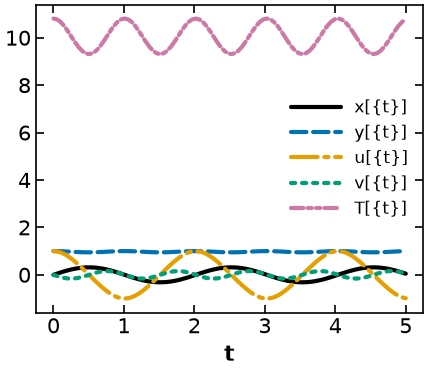

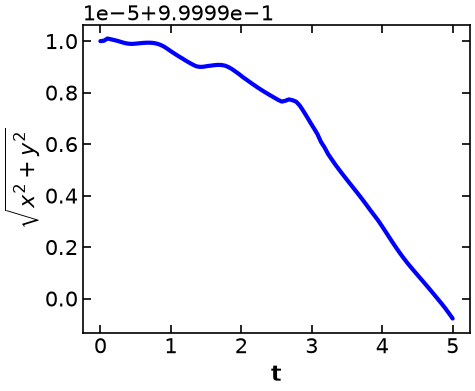

In [19]:
index1_b = create_model_index1_b()

# Specify integrator options
int_ops = {"print_stats": True, "abstol": 1e-8, "reltol": 1e-6}

# Solve DAEs
sim = Simulator(index1_b, package="casadi")
tsim, profiles = sim.simulate(
    numpoints=100, integrator="idas", integrator_options=int_ops
)

# Plot solution
plot_results(sim, tsim, profiles)

(dae-constraint-comparison)=
### Compare constraint residuals and trajectory accuracy

The measured position residual is $r(t)=|x(t)^2+y(t)^2-1|$. All three series below start with the **same physical state**,

$$x_0=0.1,\quad y_0=\sqrt{0.99},\quad u_0=1,\quad
v_0=-0.1/\sqrt{0.99},\quad T_0=1/0.99+9.81\sqrt{0.99}.$$

| Formulation | Retained equations | Numerical method on $[0,5]$ |
| --- | --- | --- |
| 2, pure ODE | no algebraic equations | IDAS, absolute tolerance $10^{-8}$, relative tolerance $10^{-6}$ |
| 4, acceleration-only | acceleration constraint | IDAS, same tolerances and initial state |
| 3, coordinate-based | position, velocity and acceleration | Radau collocation, 30 elements, 3 points per element; Ipopt tolerance $10^{-10}$ |

The coordinate model's series measures only enforced nodes. Its angular-reference errors are reported separately. The integrated series use 200 output times and an adaptive internal mesh. These are different methods and grids; the figure is a constraint diagnostic, not a controlled comparison of computational cost or trajectory accuracy. Enforcing position at nodes bounds that residual there to the achieved nonlinear feasibility; an index-1 acceleration-only model does not directly enforce position. No between-node or global-accuracy conclusion follows.

In [20]:
def residual_from_simulation(m, int_ops, numpoints=200):
    """|x^2 + y^2 - 1| along an IDAS simulation of `m`. Returns (t, residual)."""
    sim = Simulator(m, package="casadi")
    tsim, profiles = sim.simulate(
        numpoints=numpoints, integrator="idas", integrator_options=int_ops
    )
    # Column order is whatever the Simulator reports, not the order the model
    # declares -- ask it rather than assuming.
    order = [str(v) for v in sim.get_variable_order()]
    order += [str(v) for v in sim.get_variable_order(vartype="algebraic")]
    col = {name: k for k, name in enumerate(order)}
    x = profiles[:, col["x[{t}]"]]
    y = profiles[:, col["y[{t}]"]]
    return (
        [float(t) for t in tsim],
        [float(abs(xi**2 + yi**2 - 1.0)) for xi, yi in zip(x, y)],
    )


def residual_from_discretized(m):
    """|x^2 + y^2 - 1| at every collocation point of a solved model."""
    ts = sorted(m.t)
    return (
        [float(t) for t in ts],
        [float(abs(m.x[t]() ** 2 + m.y[t]() ** 2 - 1.0)) for t in ts],
    )


def set_comparison_initial_state(m):
    """Same consistent physical state for all residual-comparison series."""
    initial = {"x": 0.1, "y": np.sqrt(0.99), "u": 1.0,
               "v": -0.1 / np.sqrt(0.99), "T": 1 / 0.99 + 9.81 * np.sqrt(0.99)}
    for name, value in initial.items():
        getattr(m, name)[0].set_value(float(value))
    return m


tight = {"abstol": 1e-8, "reltol": 1e-6}

t_ode, r_ode = residual_from_simulation(set_comparison_initial_state(create_model_ode()), tight)
t_i1b, r_i1b = residual_from_simulation(set_comparison_initial_state(create_model_index1_b()), tight)
# Formulation 3, already discretized and solved with Ipopt above.
t_col, r_col = residual_from_discretized(index1_take_two)

results = {
    # The residual floor. A residual is exactly 0.0 at t = 0 for every series
    # (the initial conditions are consistent), and 0 has no place on a log
    # axis. The floor is machine epsilon, which is also the smallest residual
    # that means anything here; the plotting cell clips to it and the axis
    # label says so.
    "floor": float(np.finfo(float).eps),
    "trajectory_accuracy": collocation_accuracy,
    "collocation_nfe": collocation_nfe,
    "series": [
        {
            "key": "ode",
            "label": "Formulation 2: pure ODE, no constraints",
            "note": "no algebraic equations; IDAS",
            "t": t_ode,
            "residual": r_ode,
        },
        {
            "key": "index1_accel",
            "label": "Formulation 4: index-1, acceleration only",
            "note": "keeps only $u^2+v^2-T(x^2+y^2)+gy=0$; IDAS",
            "t": t_i1b,
            "residual": r_i1b,
        },
        {
            "key": "index1_position",
            "label": "Formulation 3: position enforced at nodes",
            "note": "direct collocation, %d finite elements; Ipopt" % collocation_nfe,
            "t": t_col,
            "residual": r_col,
        },
    ],
}

for s in results["series"]:
    print(f"{s['key']:>16s}: max residual = {max(s['residual']):.2e}")

helper.save_results(
    "pendulum-index1-residual",
    results,
    notebook="notebooks/3-dev/DAE_background.ipynb",
    source_tag="handout:pendulum-index1",
    description=(
        "Position residual for three formulations with the same consistent initial state. "
        "ODE and acceleration-only DAE use IDAS; coordinate DAE uses fixed-initial-state "
        "Radau collocation. Nodal feasibility does not certify trajectory accuracy."
    ),
    source_cells=[("notebooks/3-dev/DAE_background.ipynb", tag) for tag in (
        "l5:ode-model", "l5:acceleration-model", "handout:pendulum-index1-structure",
        "l5:collocation-initialize",
        "l5:collocation-solve", "l5:residual-extract",
    )],
    solver="IDAS via CasADi and Pyomo.DAE Simulator; Ipopt via Pyomo",
    quiet=True,
)
print(f"Collocation: {results['collocation_nfe']} elements, {len(t_col)} nodes")
print(f"Max x/y state errors: {collocation_accuracy['max_x_error']:.3e}, "
      f"{collocation_accuracy['max_y_error']:.3e}")


             ode: max residual = 9.91e-05
    index1_accel: max residual = 4.11e-06
 index1_position: max residual = 2.22e-16


Collocation: 30 elements, 91 nodes
Max x/y state errors: 1.562e-02, 5.178e-03


[helper] wrote media/figures/pendulum-index1-residual.png and .pdf


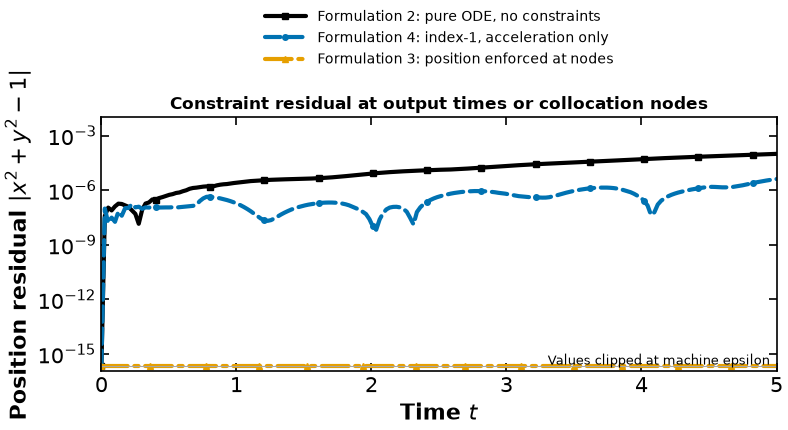

In [21]:
def plot_pendulum_index1_residual(results):
    """Residual at reported times/nodes; floor is a plotting clip, not measured accuracy."""
    floor = results["floor"]
    fig, ax = plt.subplots(figsize=(8.2, 4.8))
    for series, marker in zip(results["series"], ("s", "o", "^")):
        t = np.asarray(series["t"], dtype=float)
        residual = np.maximum(np.asarray(series["residual"], dtype=float), floor)
        ax.plot(t, residual, marker=marker, markevery=max(1, len(t)//12),
                markersize=4, label=series["label"])
    ax.axhline(floor, color="0.65", linewidth=0.8)
    ax.set_yscale("log")
    ax.set_xlim(0, 5)
    ax.set_ylim(floor/2, max(1e-2, 5*max(max(s["residual"]) for s in results["series"])))
    ax.set_xlabel("Time $t$")
    ax.set_ylabel(r"Position residual $|x^2+y^2-1|$")
    ax.set_title("Constraint residual at output times or collocation nodes", fontsize=12)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.15), fontsize=10, frameon=False)
    ax.text(0.99, 0.015, "Values clipped at machine epsilon", ha="right", va="bottom",
            transform=ax.transAxes, fontsize=9)
    for spine in ax.spines.values():
        spine.set_color("black")
    ax.tick_params(colors="black")
    fig.tight_layout()
    return fig

fig = plot_pendulum_index1_residual(results)
helper.save_figure(fig, "pendulum-index1-residual")

(dae-dynamic-strategies)=
## Dynamic optimization strategies

Biegler's Figure 8.10 distinguishes the location of the DAE solve:

![Classification of DAE optimization strategies](https://raw.githubusercontent.com/ndcbe/optimization/ad05ea88167b8998682df0020489e5ccf4c53a8c/media/figures/dae-optimization-strategies.png)

- **Sequential or single shooting:** parameterize the controls/parameters, integrate the DAE for each trial decision, and return objective and constraint values to an optimizer. An integration-ready, consistently initialized model is needed. Path constraints need adequate monitoring between requested output times.
- **Multiple shooting:** introduce interval starting states as optimization variables, integrate separate intervals, and add continuity equations. This exposes more variables and constraints but can improve initialization and permit interval parallelism.
- **Simultaneous or direct transcription:** represent the states, algebraic variables and controls on a mesh and solve the discretized dynamics together with the optimization conditions in one NLP. Collocation supplies derivative approximations and algebraic equations at nodes. Mesh error, scaling and model regularity remain important.

![An optimizer repeatedly calling a DAE integrator in sequential dynamic optimization](https://raw.githubusercontent.com/ndcbe/optimization/ad05ea88167b8998682df0020489e5ccf4c53a8c/media/sequential_dae_optimization.png)

The time-independent parameters $\mathbf p$ are shared across the mesh; $\mathbf z(t)$, $\mathbf y(t)$ and $\mathbf u(t)$ have time-indexed values. Integration or collocation formulas connect neighboring state values. Algebraic equations, variable bounds and path constraints are enforced at the selected evaluation points; boundary conditions connect the endpoints. For an NLP, singular $\mathbf g_y$ removes the local elimination guarantee, which can signal poor conditioning or an unsuitable coordinate partition. It does not by itself prove multiple physical trajectories.

Source: Biegler, §8.6, pp. 243–246 and Fig. 8.10, p. 245; Chapter 9, *Dynamic Optimization Methods with Embedded DAE Solvers* (multiple shooting §9.4, p. 271); Chapter 10, *Simultaneous Methods for Dynamic Optimization*. The Lecture 6 integration methods and Lecture 7 collocation guide develop the numerical approximations.

(dae-formulation-decisions)=
### Choosing and checking a formulation

![Decision tree for index reduction, consistent initialization, drift and coordinate singularity](https://raw.githubusercontent.com/ndcbe/optimization/ad05ea88167b8998682df0020489e5ccf4c53a8c/media/figures/dae-decision-tree.png)

| Model | Directly retained constraints | Index and main risk |
| --- | --- | --- |
| Original pendulum | position | 3; a standard index-1 DAE integrator cannot directly use this formulation |
| Five-state ODE | none | 0 on $r^2>0$; inconsistent data and discretization error can generate drift |
| Coordinate DAE | position, velocity, acceleration | 1 only on $x\ne0$; point singularity and omitted-dynamics error |
| Acceleration-only DAE | acceleration | 1 on $r^2>0$; position/velocity residuals are not directly enforced |

For a simulation, use a formulation that stays regular along the trajectory or a method that switches coordinates or preserves constraints. For direct collocation, check physical initial values, nonlinear feasibility, trajectory error and mesh refinement separately. A solver's optimal termination for a constant objective is a feasibility result for that discrete system.

(dae-engineering-models)=
### Transfer to other engineering models

For each example, name the dynamic balance, an algebraic relation and the physical variable it determines. The classification depends on the chosen states and equations.

| Domain | Differential variables/balances | Algebraic variables/relations |
| --- | --- | --- |
| Mechanical | positions and velocities; momentum balance | joint forces or multipliers; holonomic joint geometry |
| Electrical | capacitor charge or inductor flux; storage laws | node potentials/currents; Kirchhoff laws and ideal-element relations |
| Civil/environmental | tank levels; water inventory balances | junction pressures and pipe flows; junction conservation and pressure-flow laws |
| Chemical/process | species/energy inventories; material/energy balances | equilibrium phase compositions/properties; phase-equilibrium and constitutive equations |

(dae-engineering-regularity)=
### Check local elimination in a proposed model

 Differentiate its algebraic equations with respect to the chosen algebraic variables, then identify a regime where that Jacobian can lose rank. For a hydraulic network, the equations may include junction balances and pressure-flow closures. If every pressure equation uses only differences and no pressure is fixed, adding the same constant to all nodal pressures changes no equation. The algebraic Jacobian then has a null direction in pressure and is singular. An ungrounded disconnected component can have its own such freedom. A physical reference pressure or a different formulation is needed; a redundant equation alone does not supply it. This conclusion concerns the specified equations and partition, not every hydraulic network.

(dae-reading-guide)=
## Reading and references

Biegler (2010), Chapter 8, pp. 214–216 and 232–245 supplies the problem forms, index and index-reduction algorithm. Ascher & Petzold (1998), §1.3, p. 10 and §9.1–§9.2, pp. 241–254 develops the pendulum, stability, index reduction and stabilization. Nocedal & Wright (2006), Theorem A.2, p. 631 states the local implicit function theorem. The papers cited at their point of use cover DAE numerical methods, initialization, state selection and the software used in this notebook.